# This script is for analysing the experimental data of both muscles and doing some comparisons

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold


## Experimental distribution neuron per neuron

In [3]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

# df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
# df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
# df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
# df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
# df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
# df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
# df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
# df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')


In [24]:
np.round(np.mean([df1.shape[0], df2.shape[0], df3.shape[0], df4.shape[0], df5.shape[0], df6.shape[0], df7.shape[0]]),2)


np.float64(109.86)

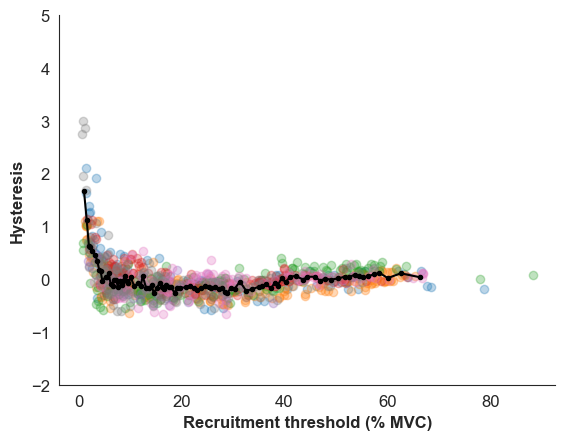

In [4]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

# df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
# df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
# df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
# df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
# df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
# df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
# df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
# df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(binned_force,binned_hyst, '.-', color='black')#label='Evolving Mean')


#######
plt.ylim(-2, 5)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


## Experimental distribution comparison in the TA and VL

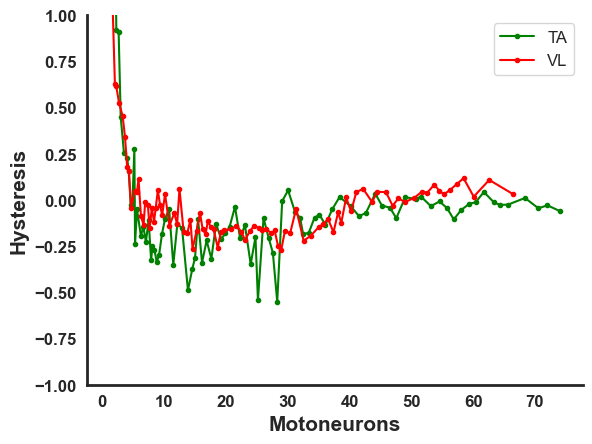

In [51]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df11 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df22= process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df33 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df44 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df55 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df66 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df77 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df88 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

all_values_hysteresisKE=np.concatenate([df["hysteresis"] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])
all_values_recrKE= np.concatenate([df.iloc[:, 0] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

combined_dKE = pd.DataFrame({ 'force': all_values_recrKE,'hysteresis': all_values_hysteresisKE})
sorted_dfKE = combined_dKE.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

valsKE =np.array(sorted_dfKE['hysteresis'])
vals_forceKE =np.array(sorted_dfKE['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


binned_hystKE = [np.mean(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]
binned_hyst_varKE = [np.var(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]

binned_forceKE = [np.mean(vals_forceKE[i:i+d]) for i in range(0, len(vals_forceKE), d) if i+d <= len(vals_forceKE)]

# plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
# plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
# plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
# plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
# plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
# plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
# plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
# plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')

plt.plot(binned_force,binned_hyst, '.-', color='green')#label='Evolving Mean')
plt.plot(binned_forceKE,binned_hystKE, '.-', color='red')#label='Evolving Mean')


#######
plt.ylim(-1, 1)
plt.xlabel('Motoneurons', fontsize=15, fontweight='bold')  # Normal weight for axis labels
plt.ylabel('Hysteresis', fontsize=15, fontweight='bold')  # Normal weight for axis labels

# Make the tick labels bold
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')
plt.legend(['TA','VL'],fontsize=12)

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

# plt.xticks(ticks=[0, 20, 40, 60, 80], labels= [] fontsize=12, fontweight='bold')


# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/exp_hysteresis_reduced_legend.png', dpi=300, bbox_inches='tight')

plt.show()


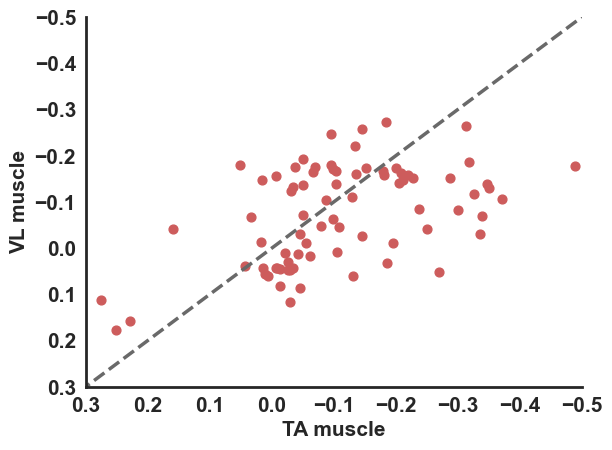

In [79]:
plt.scatter(binned_hyst, binned_hystKE[0:87], color='indianred', s=40, label='Binned Force vs Force KE')
plt.xlabel('TA muscle', fontsize=15, fontweight='bold')  # Normal weight for axis labels
plt.ylabel('VL muscle', fontsize=15, fontweight='bold')  # Normal weight for axis labels

max_val = max(np.max(binned_hyst), np.max(binned_hystKE[0:87]))
min_val = min(np.min(binned_hyst), np.min(binned_hystKE[0:87]))

plt.plot([min_val, max_val], [min_val, max_val], '--',color='dimgray',label='Diagonal (y = x)', linewidth=2.5)

plt.xticks(fontsize=15, fontweight='bold')
plt.yticks(fontsize=15, fontweight='bold')
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)


plt.xlim([0.3, -0.5])  # Reverse x-axis: positive values on the left
plt.ylim([0.3, -0.5])
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

plt.savefig('/Users/nmt121/Desktop/figures/expdata.png', dpi=300, bbox_inches='tight')


In [ ]:
mask = (np.array(binned_hyst) <= 0.1) & (np.array(binned_hystKE[0:87]) <= 0.1)
newbinned_hyst =np.array(binned_hyst)[mask]
newbinned_hystKE =np.array(binned_hystKE[0:87])[mask]

plt.scatter(newbinned_hyst, newbinned_hystKE, color='green', s=10, label='Binned Force vs Force KE')
plt.xlabel('TA muscle', fontsize=15, fontweight='bold')  # Normal weight for axis labels
plt.ylabel('VL muscle', fontsize=15, fontweight='bold')  # Normal weight for axis labels


max_val = max(np.max(newbinned_hyst), np.max(newbinned_hystKE))
plt.plot([0, max_val], [0, max_val], 'b--', label='Diagonal (y = x)', linewidth=2)

plt.xticks(fontsize=15, fontweight='bold')
plt.yticks(fontsize=15, fontweight='bold')
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

In [48]:
newbinned_hystKE

(87,)

In [54]:
newbinned_hystKE =np.array(binned_hystKE[0:87])[mask]
newbinned_hystKE.shape

(75,)

In [29]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/histogramVL_hysteresis.csv", filtered_data, delimiter=",")


In [13]:
all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_derecr= np.concatenate([df.iloc[:, 1] for df in [df1, df2, df3, df4, df5, df6, df7, df8]]) #not necessary

combined_df = pd.DataFrame({ 'force': all_values_recr,'forceder': all_values_derecr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])
vals_forceder=np.array(sorted_df['forceder'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]
binned_forceder = [np.mean(vals_forceder[i:i+d]) for i in range(0, len(vals_forceder), d) if i+d <= len(vals_forceder)]

In [16]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_forceVL.csv", binned_force, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresisVL.csv", binned_hyst, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_forceVL.csv", binned_forceder, delimiter=",")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(-0.9, 0.9)

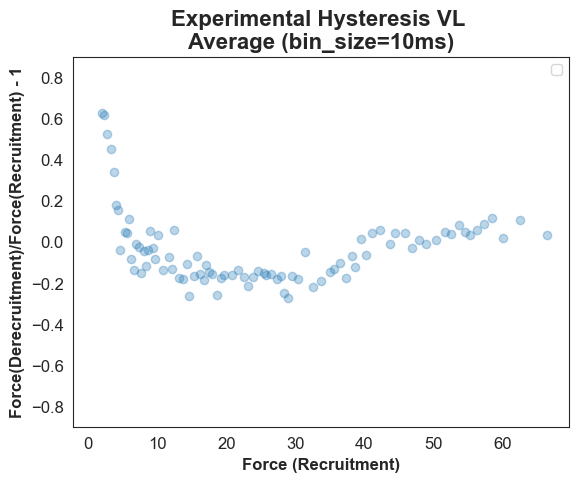

In [15]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


plt.scatter(binned_force,binned_hyst,alpha=0.3)

plt.title('Experimental Hysteresis VL \nAverage (bin_size=10ms)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()
plt.ylim(-0.9,0.9)